# Lab 01: Introduction to Web Data Science

*INFO 4617/5617 · Week 1 · Chapter 1, [Introduction to Web Data Science](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-01-introduction.html)*

Today we code together. Each step below says what we're building and why, and its code cell holds only the comments that frame it: we write the code live, in class. Nothing here is turned in.

We'll run the loop that every chapter of the book repeats, **retrieve, parse, analyze**, once from end to end, on the chapter's case: the Wikipedia article [University of Colorado Boulder](https://en.wikipedia.org/wiki/University_of_Colorado_Boulder). We fetch the page, ask Wikimedia's pageviews API how often it was read each day of January 2026, turn the answer into a DataFrame, plot it, and save it. Then we stretch the same code to a whole year, and break a request on purpose to see what failure looks like.

After each step, a **💬 Discuss** box holds questions to talk over before the next one; click it to open it. Most steps also have a **⏱ Microsprint**: a few minutes to change one thing, alone or with a neighbor, and a result to share with the class.

**Before class:** install Anaconda and make the `webdata` environment (the chapter's [Setting Up Your Environment](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-01-introduction.html#setting-up-your-environment)), start `jupyter notebook` from it, open this notebook, and have your email address ready for the User-Agent.

On Friday, run every cell above where we stopped (**Run → Run All Above Selected Cell**).

> **Instructor key.** Every cell is filled in and was run against the live sites on 2026-10-21. Every pageviews request ends on a past date (January 31, 2026 for the chapter's month, December 31, 2025 for the year), so those counts will match a rerun unless Wikimedia revises them; the page's length (Step 1), the time a request took (`elapsed`, Microsprint 2), and the library versions (Step 0) will not. The lab follows the textbook at commit `d9306b7`. Every cell was run live.

## Step 0 — Set up (7 minutes)

Check the environment before anything else. Print a line, as the chapter's first code cell does, then import the libraries the first chapters use ([Core Libraries](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-01-introduction.html#core-libraries)). If an import fails with `ModuleNotFoundError`, this notebook isn't running `webdata`'s Python: see the chapter's [Common Issues to Debug](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-01-introduction.html#common-issues-to-debug). Print the versions of `requests` and `pandas` too, because they're part of the record of what your analysis ran on.

Then define `headers`, the User-Agent every request today will send. Wikipedia refuses requests that don't say who sent them. Wikimedia's [User-Agent policy](https://foundation.wikimedia.org/wiki/Policy:Wikimedia_Foundation_User-Agent_Policy) asks for a name and version, a way to reach you, and the library that sends the request: `WebDataScience/1.0 (your-email@colorado.edu) python-requests/2.34.2`. Put your own address in place of `your-email@colorado.edu`.

In [1]:
# Print "Hello, web data science!"
# Import requests, pandas (as pd), matplotlib.pyplot (as plt), and BeautifulSoup from bs4; print the versions of requests and pandas
# Define headers: a dict whose "User-Agent" is "WebDataScience/1.0 (your-email@colorado.edu)",
#   a space, then "python-requests/" and requests.__version__; print it
print("Hello, web data science!")

import requests
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
print("requests", requests.__version__, "| pandas", pd.__version__)

headers = {"User-Agent": f"WebDataScience/1.0 (your-email@colorado.edu) python-requests/{requests.__version__}"}
print(headers)

Hello, web data science!


requests 2.34.2 | pandas 3.0.6
{'User-Agent': 'WebDataScience/1.0 (your-email@colorado.edu) python-requests/2.34.2'}


<details>
<summary>💬 Discuss</summary>

- Why does a User-Agent carry an email address? Who might write to it, and when?
- You printed the library versions. Why would someone rerunning your analysis next year want them, and where else should they be written down?
- Week 2 is about the ethics of retrieval. Before we get there: what do you think a site owes the people who collect its data, and what do they owe the site?

</details>

## Step 1 — Your first request (8 minutes)

[`requests.get()`](https://requests.readthedocs.io/en/latest/user/quickstart/#make-a-request) sends what a browser sends when you type an address, but instead of drawing the reply as a page, it hands you the whole reply as a [Response](https://requests.readthedocs.io/en/latest/api/#requests.Response) object. Fetch the chapter's article, sending `headers`, and print three things: the **status code**, the server's three-digit verdict (2xx is success, 4xx means something is wrong with your request), the object's type, and the number of characters in the page. Add [`timeout=30`](https://requests.readthedocs.io/en/latest/user/quickstart/#timeouts) so a server that never answers can't hang your notebook. The chapter's [Meet `requests`](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-01-introduction.html#meet-requests) explains each part.

In [2]:
# Request https://en.wikipedia.org/wiki/University_of_Colorado_Boulder, sending headers, with timeout=30
# Print the status code, the type of the response, and the number of characters in response.text
url = "https://en.wikipedia.org/wiki/University_of_Colorado_Boulder"
response = requests.get(url, headers=headers, timeout=30)

print(response.status_code)
print(type(response))
print(len(response.text))

200
<class 'requests.models.Response'>
765803


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** send the same request with **no** headers at all, and see what Wikipedia does with `requests`' default User-Agent.
**Share:** the status code and its reason, the User-Agent `requests` sent on its own, and the first line of the body.

In [3]:
# Microsprint: send the same request without headers, and call the response bare
# Print its status code and reason, the User-Agent requests sent (bare.request.headers), and the body's first 100 characters
bare = requests.get(url, timeout=30)
print(bare.status_code, bare.reason)
print(bare.request.headers["User-Agent"])
print(bare.text[:100])

403 Forbidden
python-requests/2.34.2
Please set a user-agent and respect our robot policy https://w.wiki/4wJS. See also https://phabricat


<details>
<summary>💬 Discuss</summary>

- The same address gave a 200 with our header and a 403 without it. Was the 403 a bug in your code, or a decision by the server? How can you tell?
- Anyone can type any address into a User-Agent. What does the header actually prove, and why does Wikipedia ask for it anyway?
- The chapter says web data science differs from other data science because the first challenge is getting the data. What did the 403 add to that idea?

</details>

## Step 2 — Open the parcel (11 minutes)

A Response is the parcel the server sent back, still in its packaging. Tour the parts you'll use most: the `Content-Type` header (what kind of document came back), the body as text (`.text`, a string) and as raw bytes (`.content`), where you ended up (`.url`), and how you got there (`.history`). Then print the start of the body: raw HTML, the page before a browser draws it.

Our `.history` is empty, because we asked for the right address. Ask for the same page at `http://` instead of `https://`, and see what the server does. The chapter's [Meet `requests`](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-01-introduction.html#meet-requests) walks through each attribute, and the `requests` guide covers [redirection and history](https://requests.readthedocs.io/en/latest/user/quickstart/#redirection-and-history).

In [4]:
# Print the Content-Type header, the types of response.text and response.content,
#   response.url and response.history, and the first 500 characters of response.text
# Then request the same page at http:// instead of https:// (with headers), and print its .url and .history
print(response.headers["Content-Type"])
print(type(response.text))
print(type(response.content))
print(response.url)
print(response.history)
print(response.text[:500])

redirected = requests.get("http://en.wikipedia.org/wiki/University_of_Colorado_Boulder",
                          headers=headers, timeout=30)
print(redirected.url)
print(redirected.history)

text/html; charset=UTF-8
<class 'str'>
<class 'bytes'>
https://en.wikipedia.org/wiki/University_of_Colorado_Boulder
[]
<!DOCTYPE html>
<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 skin-theme-clientp


https://en.wikipedia.org/wiki/University_of_Colorado_Boulder
[<Response [301]>]


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** a short version of Additional Exercise 1. List the Response's public attributes with [`dir()`](https://docs.python.org/3/library/functions.html#dir), pick three that the chapter didn't use, print their values, and look each one up with [`help()`](https://docs.python.org/3/library/functions.html#help) or the [Response documentation]({RQ}/api/#requests.Response).
**Share:** one attribute, its value for our response, and what the documentation says it means, in one sentence.

In [5]:
# Microsprint: list the names in dir(response) that don't start with "_"
# Pick three the chapter didn't use; print each one's value, and read about it with help() or the docs
names = [name for name in dir(response) if not name.startswith("_")]
print(names)

print(response.elapsed)   # how long the reply took to arrive
print(response.encoding)  # the character encoding requests used to decode .text
print(response.reason)    # the words that go with the status code

['apparent_encoding', 'close', 'connection', 'content', 'cookies', 'elapsed', 'encoding', 'headers', 'history', 'is_permanent_redirect', 'is_redirect', 'iter_content', 'iter_lines', 'json', 'links', 'next', 'ok', 'raise_for_status', 'raw', 'reason', 'request', 'status_code', 'text', 'url']
0:00:00.360646
UTF-8
OK


<details>
<summary>💬 Discuss</summary>

- When would `.content` matter more than `.text`? Week 9 downloads PDFs: what would go wrong if we saved one from `.text`?
- The `http://` request ended at `https://` with a 301 in its history. Why do sites redirect, and why might a study want to record where each request actually landed?
- The first 500 characters are mostly setup, not the article. In week 6 we parse pages like this with BeautifulSoup: what would you need to find to reach the article's text?

</details>

## Step 3 — Call your first API (8 minutes)

A web page is written for people; an API answers programs. Wikimedia's [pageviews API](https://doc.wikimedia.org/generated-data-platform/aqs/analytics-api/reference/page-views.html) returns how many times an article was viewed each day, and its parameters are parts of the address: the project, the access method, the agent, the article, the granularity, and a start and end date. Build the chapter's URL for January 2026, request it with `headers`, and check the status code before you parse anything: [`raise_for_status()`](https://requests.readthedocs.io/en/latest/user/quickstart/#response-status-codes) stops the cell with the status if the API refused, rather than letting a confusing error turn up later. Then [`.json()`](https://requests.readthedocs.io/en/latest/user/quickstart/#json-response-content) turns the body into a Python dictionary. See the chapter's [Calling Your First API](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-01-introduction.html#calling-your-first-api).

In [6]:
# Build the chapter's URL: api_url, then /en.wikipedia/all-access/all-agents/{article}/daily/20260101/20260131
# Request it with headers; print the status code and Content-Type, then call raise_for_status()
# Parse the body with .json(); print its type, its keys, the number of items, and the first item
api_url = "https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article"
article = "University_of_Colorado_Boulder"
url = f"{api_url}/en.wikipedia/all-access/all-agents/{article}/daily/20260101/20260131"

response = requests.get(url, headers=headers, timeout=30)
print(response.status_code, response.headers["Content-Type"])
response.raise_for_status()

data = response.json()
print(type(data))
print(data.keys())
print(len(data["items"]))
print(data["items"][0])

200 application/json; charset=utf-8
<class 'dict'>
dict_keys(['items'])
31
{'project': 'en.wikipedia', 'article': 'University_of_Colorado_Boulder', 'granularity': 'daily', 'timestamp': '2026010100', 'access': 'all-access', 'agent': 'all-agents', 'views': 657}


<details>
<summary>💬 Discuss</summary>

- The `Content-Type` says JSON this time, not HTML. Why look at it before calling `.json()`?
- Which part of the URL would you change to ask about another article, another month, or another language's Wikipedia?
- Week 4 is about JSON. Say in words the path from `data` to the number of views on January 1.

</details>

## Step 4 — From JSON to a DataFrame (10 minutes)

`data["items"]` is a list of dictionaries, one per day, and [`pd.DataFrame()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html) turns a list like that into a table in one call. The `timestamp` column is text, such as `"2026010100"`: [`pd.to_datetime()`](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html) with a `format` makes it a real date that pandas can sort, plot, and do arithmetic with. Then use the DataFrame: summarize the views with `describe()`, and find the busiest day with [`idxmax()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.idxmax.html). See the chapter's [From Response to DataFrame](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-01-introduction.html#from-response-to-dataframe).

In [7]:
# Make df, a DataFrame from data["items"], and print its first rows
# Add a "date" column: pd.to_datetime() on "timestamp" with format="%Y%m%d00"; print df.dtypes
# Print describe() of the views, and the row of the busiest day (df.loc and idxmax())
df = pd.DataFrame(data["items"])
print(df.head())

df["date"] = pd.to_datetime(df["timestamp"], format="%Y%m%d00")
print(df.dtypes)

print(df["views"].describe())
print(df.loc[df["views"].idxmax()])

        project                         article granularity   timestamp  \
0  en.wikipedia  University_of_Colorado_Boulder       daily  2026010100   
1  en.wikipedia  University_of_Colorado_Boulder       daily  2026010200   
2  en.wikipedia  University_of_Colorado_Boulder       daily  2026010300   
3  en.wikipedia  University_of_Colorado_Boulder       daily  2026010400   
4  en.wikipedia  University_of_Colorado_Boulder       daily  2026010500   

       access       agent  views  
0  all-access  all-agents    657  
1  all-access  all-agents    761  
2  all-access  all-agents    584  
3  all-access  all-agents    629  
4  all-access  all-agents    783  
project                   str
article                   str
granularity               str
timestamp                 str
access                    str
agent                     str
views                   int64
date           datetime64[us]
dtype: object
count     31.000000
mean     671.677419
std       95.871924
min      496.000000
25%  

### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** find out whether the article is read more on weekdays or at weekends. Name each day's weekday with [`.dt.day_name()`]({PD}/pandas.Series.dt.day_name.html), and average the views for each weekday.
**Share:** the busiest and the quietest day of the week, with their average views.

In [8]:
# Microsprint: name each date's weekday with df["date"].dt.day_name()
# Average the views by weekday (groupby), and sort them from busiest to quietest
weekday = df["date"].dt.day_name()
print(df.groupby(weekday)["views"].mean().round().sort_values(ascending=False))

date
Tuesday      739.0
Wednesday    736.0
Monday       709.0
Thursday     708.0
Friday       651.0
Sunday       598.0
Saturday     579.0
Name: views, dtype: float64


<details>
<summary>💬 Discuss</summary>

- What would have gone wrong if we had plotted or sorted `timestamp` as text?
- Weekdays and weekends differ. Who might be reading this article on a Tuesday that isn't on a Saturday? How could you check a guess like that?
- The data says which day was busiest, not why. How would you check that a real event caused it, rather than guessing from memory? (Week 10 adds a clue: the article's edits.)

</details>

## Step 5 — Plot the month (6 minutes)

A plot shows in a glance what the table makes you read row by row. Draw the chapter's line plot of views by date with [`plt.plot()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html), with labeled axes and a title naming the article: a figure without them can't be read by anyone who didn't make it.

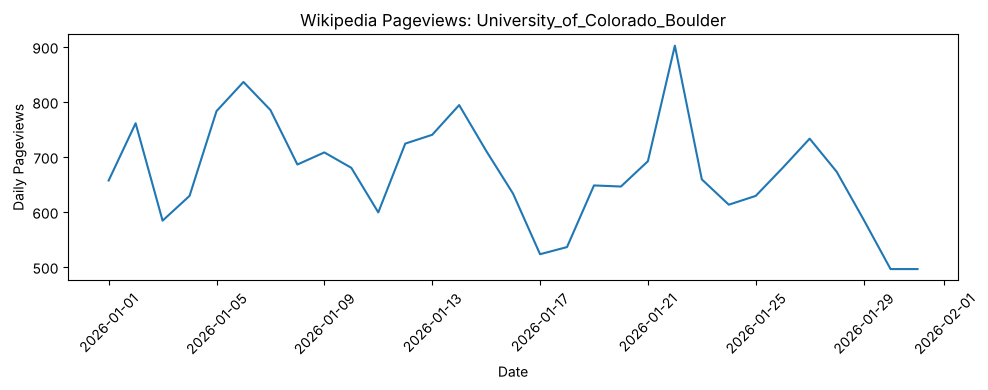

In [9]:
# Plot views against date (figsize 10 by 4), label the axes "Date" and "Daily Pageviews",
#   title it with the article, rotate the date labels 45 degrees, and show it
plt.figure(figsize=(10, 4))
plt.plot(df["date"], df["views"])
plt.xlabel("Date")
plt.ylabel("Daily Pageviews")
plt.title(f"Wikipedia Pageviews: {article}")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<details>
<summary>💬 Discuss</summary>

- What does the plot show that `describe()` didn't?
- We asked for `all-agents`, so these counts include crawlers and bots as well as people. Week 10 splits them apart. Until then, which claims about "interest in CU Boulder" can this plot support?
- The chapter calls pageviews "digital traces": byproducts of ordinary activity, not made for research. What does a trace like this miss that a survey of readers would catch?

</details>

## Step 6 — Save your work (8 minutes)

Once the data is in a DataFrame, save it, so you never have to ask the API for the same thing again: [`to_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html) writes it, and [`pd.read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html) reads it back. The chapter's [Saving Your Work](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-01-introduction.html#saving-your-work) gives three reasons: courtesy to the server, reproducibility if the API changes, and a snapshot of data that may itself change.

In [10]:
# Save df to "cu_boulder_pageviews.csv" without the index
# Load it back into df with pd.read_csv(), and print how many rows came back
df.to_csv("cu_boulder_pageviews.csv", index=False)

df = pd.read_csv("cu_boulder_pageviews.csv")
print(f"Loaded {len(df)} rows from disk.")

Loaded 31 rows from disk.


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** check what the round trip kept. Print `df.dtypes` now and compare them with Step 4's. Then load the file again with `parse_dates=["date"]` and print the `date` column's dtype.
**Share:** which columns came back as a different type, and the one argument that fixes the date.

In [11]:
# Microsprint: print df.dtypes and compare them with Step 4's output
# Load the file again with parse_dates=["date"], and print the date column's dtype
print(df.dtypes)

df = pd.read_csv("cu_boulder_pageviews.csv", parse_dates=["date"])
print(df["date"].dtype)

project          str
article          str
granularity      str
timestamp      int64
access           str
agent            str
views          int64
date             str
dtype: object
datetime64[us]


<details>
<summary>💬 Discuss</summary>

- Of the chapter's three reasons to save (courtesy, reproducibility, a snapshot), which matters most for this month's data, and why?
- A CSV doesn't remember its column types, or when, where, and how its data was collected. What would you write down beside the file so a stranger could trust it?
- Week 7 uses the Wayback Machine's saved copies of web pages. How is our CSV like one of those copies, and how is it different?

</details>

## Step 7 — A year at a glance (12 minutes)

To ask the same question of another time window or another article, don't copy Steps 3 and 4 again: wrap them in a function. That's the **abstraction** of the chapter's [computational thinking](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-01-introduction.html#the-data-science-mindset): name the steps once, and call them with new inputs. Write `get_daily_views(article, start, end)`, ask it for all of 2025, and add the daily views up by week with [`resample("W")`](https://pandas.pydata.org/docs/reference/api/pandas.Series.resample.html), one of the operations the chapter mentions at the end of [From Response to DataFrame](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-01-introduction.html#from-response-to-dataframe).

A function you'll call in a loop should also be polite. When too many requests arrive, Wikimedia answers **429 Too Many Requests**, with a `Retry-After` header saying how many seconds to wait. So if the answer is a 429, [`time.sleep()`](https://docs.python.org/3/library/time.html#time.sleep) that long and ask once more.

365 days, 278,066 views


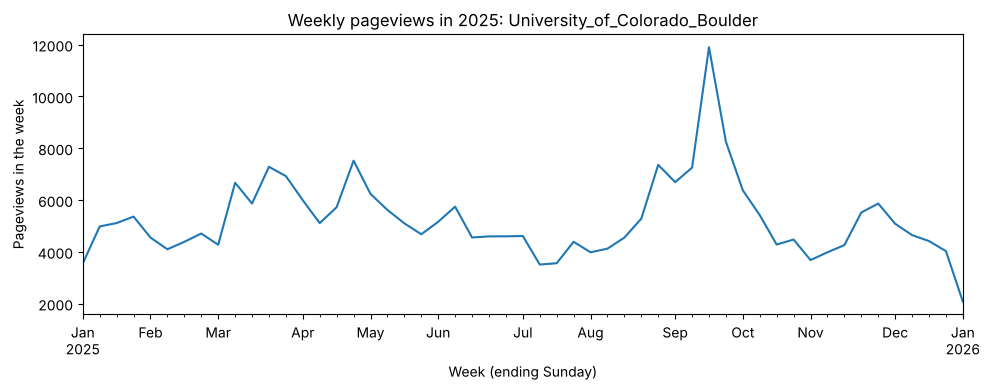

In [12]:
# Import time. Define get_daily_views(article, start, end): Step 3's URL and request; if it's a 429, time.sleep()
#   for int(response.headers["Retry-After"]) seconds and ask once more; raise_for_status(); return Step 4's DataFrame
# Call it for article, 20250101 to 20251231; print the number of days and the total views
# Add up the views by week (set_index("date"), resample("W"), sum) and plot them with a title and labeled axes
import time

def get_daily_views(article, start, end):
    url = f"{api_url}/en.wikipedia/all-access/all-agents/{article}/daily/{start}/{end}"
    response = requests.get(url, headers=headers, timeout=30)
    if response.status_code == 429:  # too many requests: wait as long as the API asks, then try once more
        time.sleep(int(response.headers.get("Retry-After", 60)))
        response = requests.get(url, headers=headers, timeout=30)
    response.raise_for_status()
    views = pd.DataFrame(response.json()["items"])
    views["date"] = pd.to_datetime(views["timestamp"], format="%Y%m%d00")
    return views[["date", "views"]]

year = get_daily_views(article, "20250101", "20251231")
print(f"{len(year)} days, {year['views'].sum():,} views")

weekly = year.set_index("date")["views"].resample("W").sum()
fig, ax = plt.subplots(figsize=(10, 4))
weekly.plot(ax=ax)
ax.set_title(f"Weekly pageviews in 2025: {article}")
ax.set_xlabel("Week (ending Sunday)")
ax.set_ylabel("Pageviews in the week")
plt.tight_layout()
plt.show()

### ⏱ Microsprint (6 minutes, alone or in pairs)

**Do:** a short version of Additional Exercise 3. Get 2025 for two more Colorado universities, `Colorado_State_University` and `University_of_Denver`, pausing a second between requests. Add up each one's views by month with `resample("ME")`, plot the three on one set of axes with a legend, and print each one's total for the year.
**Share:** which of the three drew the most views in 2025, and the month each one peaked.

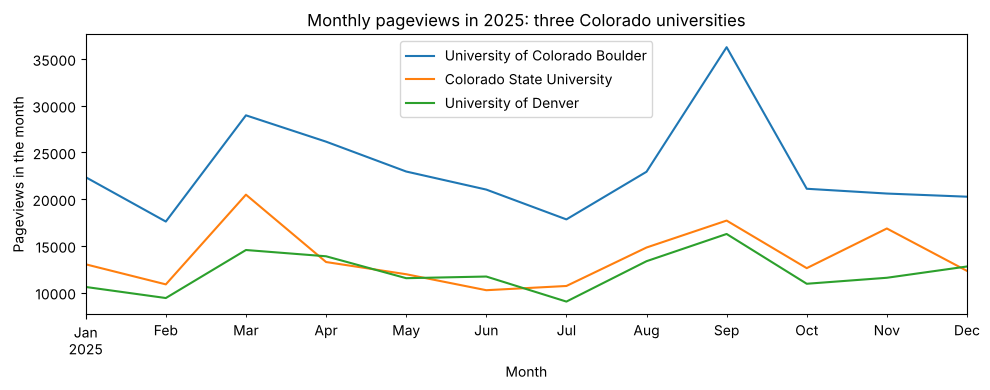

University of Colorado Boulder    278066
Colorado State University         164937
University of Denver              145744
dtype: int64
University of Colorado Boulder    September
Colorado State University             March
University of Denver              September
dtype: str


In [13]:
# Microsprint: for article, "Colorado_State_University", and "University_of_Denver",
#   get 2025 with get_daily_views(), sum by month with resample("ME"), and time.sleep(1) between requests
# Put the three in one DataFrame, plot it with a title, labeled axes, and a legend,
#   and print each one's total views and its busiest month
monthly = {}
for name in [article, "Colorado_State_University", "University_of_Denver"]:
    views = get_daily_views(name, "20250101", "20251231")
    monthly[name.replace("_", " ")] = views.set_index("date")["views"].resample("ME").sum()
    time.sleep(1)
monthly = pd.DataFrame(monthly)

ax = monthly.plot(figsize=(10, 4), title="Monthly pageviews in 2025: three Colorado universities")
ax.set_xlabel("Month")
ax.set_ylabel("Pageviews in the month")
plt.tight_layout()
plt.show()

print(monthly.sum().sort_values(ascending=False))
print(monthly.idxmax().dt.strftime("%B"))

<details>
<summary>💬 Discuss</summary>

- The first and last weeks of the weekly plot are lower than their neighbors. Is that real? (Look at which days those weeks contain.)
- One university's article drew more views than another's. What does that measure about the universities, and what doesn't it?
- We paused a second between requests, and week 2 makes that a rule. Why does it matter when thirty people in this room run the same loop at once?

</details>

## Step 8 — When a request fails (10 minutes)

Every request so far worked. Make one fail on purpose, so you know what failure looks like: misspell the article. The API still answers, with a status code and a JSON body that explains the problem, but that body has no `"items"`, so Step 4's code would stop with a `KeyError` that doesn't say why. `raise_for_status()` turns the bad status into an error that names it, and [`try` and `except`](https://docs.python.org/3/tutorial/errors.html#handling-exceptions) let the cell report it instead of stopping.

This is also the moment for the chapter's [Documentation as Professional Practice](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-01-introduction.html#documentation-as-professional-practice): read the error and the documentation first, and when you ask someone for help, say what you tried, what you expected, what happened, and what the error message says.

In [16]:
# Request January 2026 for the misspelled article "University_of_Colorado_Bolder"
# Print the status code and Content-Type, the body's "title" and "detail", and whether "items" is in it
# Then call raise_for_status() inside try / except requests.HTTPError, and print the error
url = f"{api_url}/en.wikipedia/all-access/all-agents/University_of_Colorado_Bolder/daily/20260101/20260131"
response = requests.get(url, headers=headers, timeout=30)
print(response.status_code, response.headers["Content-Type"])

problem = response.json()
print(problem["title"], "|", problem["detail"])
print("items" in problem)

try:
    response.raise_for_status()
except requests.HTTPError as error:
    print("Stopped:", error)

404 application/problem+json
Not Found | The date(s) you used are valid, but we either do not have data for those date(s), or the project you asked for is not loaded yet. Please check documentation for more information
False
Stopped: 404 Client Error: Not Found for url: https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article/en.wikipedia/all-access/all-agents/University_of_Colorado_Bolder/daily/20260101/20260131


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** break the January request a different way: a date that doesn't exist, a project that doesn't exist, or a misspelled granularity. Then write, as comments, the four-part help request the chapter describes.
**Share:** the status code and the API's `detail` sentence, and whether that sentence pointed you at the real mistake.

In [17]:
# Microsprint: break the January 2026 request in one other way (a bad date, project, or granularity); print the status and "detail"
# Then write, as comments: what you tried, what you expected, what happened, and the error message
url = f"{api_url}/en.wikipedia/all-access/all-agents/{article}/daily/20260101/20260230"
response = requests.get(url, headers=headers, timeout=30)
print(response.status_code, "|", response.json()["detail"])

# Tried: daily views of University_of_Colorado_Boulder from 20260101 to 20260230
# Expected: a list of daily views for January and February, like Step 3's for January
# Happened: status 400 (Bad Request), and the body has no "items"
# Error: "end timestamp is invalid, must be a valid date in YYYYMMDD format" (February has no 30th)

400 | end timestamp is invalid, must be a valid date in YYYYMMDD format


<details>
<summary>💬 Discuss</summary>

- The misspelled article's `detail` blamed the dates or the project, not the title. What does that teach about reading error messages?
- A 403, a 404, a 400, and a 429 are all 4xx codes. Which of them can you fix by changing your code, and which only by waiting? Week 5 goes through the codes you'll meet most.
- Additional Exercise 2 asks about POST. Every request today was a GET: when would an API make you send a POST instead?

</details>

## Step 9 — What did we learn? (5 minutes)

In a few sentences, as comments in the cell below:

- What was the status code in Step 1, and in Microsprint 1? What made the difference?
- Which day in January 2026 was the busiest, and how much busier than the median day? What would you need to connect it to a real event?
- What did the CSV round trip in Step 6 lose, and what can you now do without touching the network again?
- In Microsprint 5, which university's article drew the most views in 2025? Name one reason that count might not measure what it seems to.

**Recommended Exercises ahead** (in the chapter's companion notebook, due Sunday):

- Step 1, verify your environment: Step 0's imports.
- Step 2, make your first request: Step 1's request with `headers`, and its status code and length.
- Step 3, call the pageviews API for your own article: Step 3's URL pattern and `.json()`; Step 8 shows what a misspelled title returns.
- Step 4, build a DataFrame with a date column: Step 4's `pd.DataFrame()` and `pd.to_datetime()`.
- Step 5, plot the month with labeled axes and a title: Step 5's plot.
- Step 6, save and reload: Step 6's `to_csv()` and `read_csv()`.
- Step 7, interpret: Step 4's `idxmax()` finds the busiest day, Steps 1 and 8 read status codes, and Step 6 says what saving buys you.

In [18]:
# Your answers here, as comments
# Step 1 got 200 with our headers; Microsprint 1 got 403 Forbidden without them. The only difference was the
#   User-Agent: requests' own, python-requests/2.34.2, was refused with "Please set a user-agent".
# The busiest day of January 2026 was January 22, with 902 views, 34% more than the median day (673).
#   The data can't say why: we'd need evidence from the time, such as news or the article's edits that week
#   (week 10), and to remember that the API's days are UTC days.
# The CSV kept all 31 rows, but "date" came back as text and "timestamp" as a number; parse_dates=["date"]
#   restores the dates. With the file saved, we can redo every step from Step 4 on without another request.
# CU Boulder's article drew the most views in 2025 (278,066), ahead of Colorado State (164,937) and Denver
#   (145,744). But all-agents counts bots too: chapter 10 shows this article's automated views jumping to about
#   9,800 in September 2025, which is also CU's busiest month here, so the gap isn't all human interest.

## Friday: from the lab to the textbook (15 minutes)

We ran the chapter's code against the live sites. Where did the lab and the chapter part ways? Some places to look:

- **A cell that broke.** The chapter calls `.json()` without looking at the status code first. When the rate limit answers 429, or the title is misspelled (Step 8), what error does the chapter's code give, and would a reader in week 1 know what it meant?
- **A sentence that confused.** The chapter's Saving Your Work loads the CSV back "without making another API request", but the `date` column comes back as text (Microsprint 4). Should the chapter say so, and how?
- **An output that has changed.** Compare Steps 1–3's outputs with the comments in the chapter's code, and Step 3's first days with its pageviews figure.
- **A microsprint that would make a good exercise.** The weekday averages (Microsprint 3), the three universities (Microsprint 5), or the four-part help request (Microsprint 6).

[The revision framework](../../handouts/common/revision-framework.md) says how to propose a revision.